## Lab 5 

1. What data you are going to work on.
2. A sketch for the project you plan to do. (As this is science the project may evolve over the coming weeks, but have a distinct initial plan)

2. Download some of the data and make one initial plot. Need not be fancy, but downloading and plotting some of the data is important to make sure you actually have the information you need to do your project and to understand the structure of your data.

### Data:

The UCL OPM Auditory Dataset found in MNE Python will be used. This is data using optically pumped magnetometers to measure the evoked auditory activity of the brain in the presence of a natual background. 

### Sketch of Project:

There are two goals for the project; first identify sources of noise (signal-less data) and distortions to the data, and second use data from many trials of an auditory related activation task to produce an estimate for auditory brain activity in a specific region to ask how likely it is that our estimate is valid.

For the first part, the UCL OPM dataset is used and the raw data is examined. Noise in the data and sensors is identified and then preprocessing methods to remove sources of noise and fluctuations are performed. Noise is complex in neuroimaging due to the fact that neural signals of interest and noise often are not orthogonal in the signal space. In light of this fact, assumptions have to be made about the data that complicate interpretations. These assumptions rely on background knowledge about the sources of interest, in this case the auditory network in the brain, and the noise which is made up of more standard sources of noise such as power line noise or sensors noise as well as more phenomenologically complex sources such as is produced by brain regions that are not of interest.

To obtain signal of interest in relation to a task that evokes auditory activity in the brain, one can average many trials of the same task to obtain time locked averaged activity that is theoretically the quasi-stable response of the brain to a specific type of activity. The task is chosen such that response from a particular region is maximized relative to other brain regions, in this case auditory activity is maximized and associated regions are well described in the literature. The evoked signals from task related activation can be greatly distorted by low frequency fluctuations and noise, thus denoising data is necessary to obtain reliable signals.

Denoissing MEG data can be done in many ways, all of which depend on the type of task and MEG setup being used. MEG OPM systems are unique from traditional SQUID systems as their placement is much more flexible and as such sensor denoissing techniques must take into account varying sensor placement on scalp such as between different recording sessions and participants, as well as additional sensor movement from participant activity as OPMs enable greater range of motion. In this data movement should be limited, so initial denoising techniques will rely regressing via either reference sensors or with homogenous field corrections (HFC). These methods will be compared. Additional filtering can be performed via a notch filter to remove power line noise and a bandpass filter can be applied to narrow in on frequencies of interest. The bandpass filter to be used depends on how well characterized the activity of the source is. Cardiac and ocular artefacts are also often present and contribute signals that must either be removed or the data from these events should be removed. Additionally, channels can go bad or malfunction and sometimes the data from these channels must be removed or interpolated from other channels. 

Once this basic preprocessing is performed, an evoked response can be calculated and an estimate for brain activity can be performed using either an inverse operator or via a localization method such as beamforming. Comparing the results of localization and activity estimates for varying choices in preprocessing will then demonstrate the effectiveness of those choices. After estimation of source activity in the brain, connectivity analysis can be done. However, with a single subject such analysis is limited and considering the fact that the phase and amplitude of brain noise is likely to significantly impact behavior, the validity of such work is more limited than was once thought.

In [15]:
# Importing data

import matplotlib.pyplot as plt
import numpy as np
import mne

data_path = mne.datasets.ucl_opm_auditory.data_path()
subject = "sub-002"
opm_file = (
    data_path / subject / "ses-001" / "meg" / "sub-002_ses-001_task-aef_run-001_meg.bin"
)
subjects_dir = data_path / "derivatives" / "freesurfer" / "subjects"

# For now we are going to assume the device and head coordinate frames are
# identical (even though this is incorrect), so we pass verbose='error'
raw = mne.io.read_raw_fil(opm_file, verbose="error")
raw.crop(120, 210).load_data()  # crop for speed


Reading 0 ... 540000  =      0.000 ...    90.000 secs...


<RawFIL | sub-002_ses-001_task-aef_run-001_meg.bin, 95 x 540001 (90.0 s), ~391.5 MiB, data loaded>

[Text(0.5, 1.0, 'Sampled Data without mean subtraction'),
 (-1000.0, 1000.0),
 (0.0, 89.91666666666667),
 Text(0.5, 0, 'Time (s)'),
 Text(0, 0.5, 'Amplitude (pT)')]

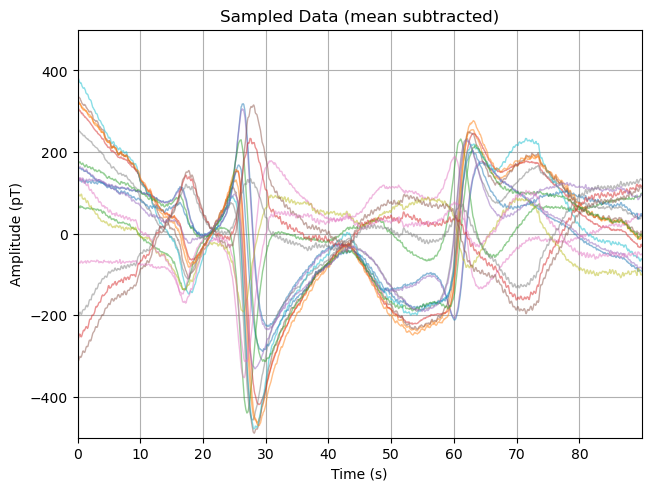

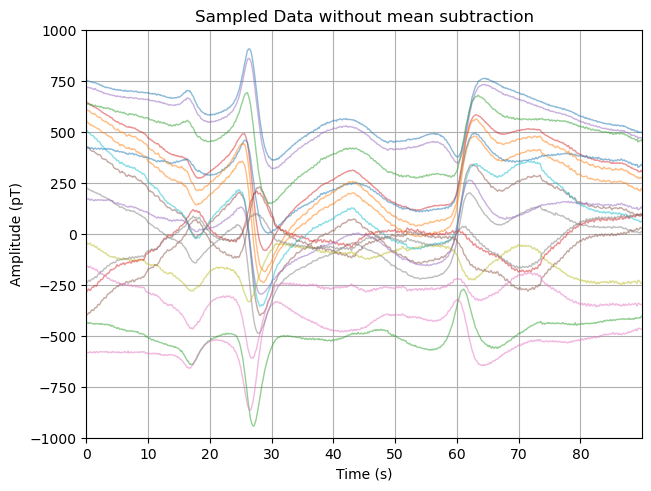

In [16]:
# Inspecting raw unprocessed data

picks = mne.pick_types(raw.info, meg=True) # this picks all MEG channels

amp_scale = 1e12  # T->pT
stop = len(raw.times) - 300
step = 500
data_ds, time_ds = raw[picks[::5], :stop]
data_ds, time_ds = data_ds[:, ::step] * amp_scale, time_ds[::step]

fig, ax = plt.subplots(layout="constrained")
plot_kwargs = dict(lw=1, alpha=0.5)
ax.plot(time_ds, data_ds.T - np.mean(data_ds, axis=1), **plot_kwargs)
ax.grid(True)
set_kwargs = dict(
    ylim=(-500, 500), xlim=time_ds[[0, -1]], xlabel="Time (s)", ylabel="Amplitude (pT)"
)
ax.set(title="Sampled Data (mean subtracted)", **set_kwargs)


picks = mne.pick_types(raw.info, meg=True) # this picks all MEG channels

amp_scale = 1e12  # T->pT
stop = len(raw.times) - 300
step = 500
data_ds, time_ds = raw[picks[::5], :stop]
data_ds, time_ds = data_ds[:, ::step] * amp_scale, time_ds[::step]

fig, ax = plt.subplots(layout="constrained")
plot_kwargs = dict(lw=1, alpha=0.5)
ax.plot(time_ds, data_ds.T, **plot_kwargs)
ax.grid(True)
set_kwargs = dict(
    ylim=(-1000, 1000), xlim=time_ds[[0, -1]], xlabel="Time (s)", ylabel="Amplitude (pT)"
)
ax.set(title="Sampled Data without mean subtraction", **set_kwargs)
